In [1]:
import time

import torch
from torch import nn

from src.Config import Config
from src.FashionMNISTDATA import FashionMNISTData
from src.Autoencoder import Autoencoder
from src.Optimizer import create_optimizer
from src.Trainer import Trainer
from src.Visualizer import Visualizer


def main(config):
    # Configuración
    device = config.setup()
    # Datos
    data = FashionMNISTData(
        batch_size=config.BATCH_SIZE,
        seed=config.SEED, color=config.COLOR
    )

    if config.showSample:
        data.inspect_example()
        data.show_samples()

    # Modelo
    torch.manual_seed(Config.SEED)

    model = Autoencoder(
        latent_dim=config.LATENT_DIM,
        p_dropout=config.DROPOUT_P
    ).to(device)

    # Comprobar dimensiones
    if config.showDimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            reconstructions = model(images.to(device))
            latent_codes = model.encode(images.to(device))

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Código latente:", latent_codes.shape)
        print("Reconstrucción:", reconstructions.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.MSELoss()

    optimizer = create_optimizer(
        model,
        config.OPTIMIZER_NAME
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Reconstrucciones antes del entrenamiento
    if config.showUntrained:
        Visualizer.show_reconstructions(
            model,
            data.valid_loader,
            device,
            data.CLASS_NAMES,
            title="Sin entrenar", color=config.COLOR
        )

    # Entrenamiento
    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    print(f"Training time: {time.perf_counter() - start:.2f} seconds")
    # Gráfico de pérdidas
    if config.showLoss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    trainer.test(data.test_loader)

    # Reconstrucciones después del entrenamiento
    if config.showTrained: Visualizer.show_reconstructions(
        model,
        data.test_loader,
        device,
        data.CLASS_NAMES,
        title="Reconstrucción", color=config.COLOR
    )

    # Espacio latente
    if config.showDimentions2:
        images, _ = next(iter(data.test_loader))

        images = images.to(device)

        model.eval()

        with torch.no_grad():
            latent_codes = model.encode(images)

        print("\nEspacio latente:")
        print("Imágenes:", images.shape)
        print("Códigos latentes:", latent_codes.shape)


# ============================================================
# EJECUCIÓN
# ============================================================

config1 = Config(latent_dim=128, dropout_p=0.5, showSample=False, showDimentions=False, showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

config2 = Config(latent_dim=128, dropout_p=0.0, showSample=False, showDimentions=False, showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

config3 = Config(latent_dim=128, dropout_p=0.4, optimizer_name="SGD", showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

config4 = Config(latent_dim=256, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

config5 = Config(latent_dim=512, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

config6 = Config(latent_dim=728, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)

config7 = Config(latent_dim=1024, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)




========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 128
Dropout:          0.5
Optimizer:        Adam

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: Adam
Dropout: 0.5

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.5 | Z dimension -> 128 | Batch size -> 100
Época 01/10 | Train MSE: 0.02533 | Valid MSE: 0.02548
Época 02/10 | Train MSE: 0.02089 | Valid MSE: 0.02107
Época 03/10 | Train MSE: 0.01907 | Valid MSE: 0.01926
Época 04/10 | Train MSE: 0.01834 | Valid MSE: 0.01857
Época 05/10 | Train MSE: 0.01747 | Valid MSE: 0.01767
Época 06/10 | Train MSE: 0.01688 | Valid MSE: 0.01708
Época 07/10 | Train MSE: 0.01656 | Valid MSE: 0.01676
Época 08/10 | Train MSE: 0.01631 | Valid MSE: 0.01651
Época 09/10 | Train MSE: 0.01615 | Valid MSE: 0.01636
Época 10/10 | Train MSE: 0.01615 | Valid M

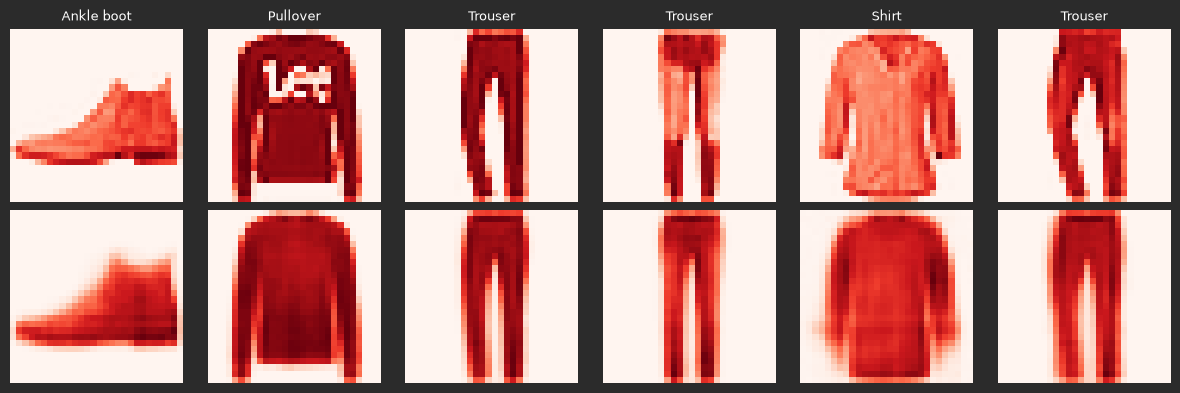

In [2]:
main(config1)


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 128
Dropout:          0.0
Optimizer:        Adam

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: Adam
Dropout: 0.0

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.0 | Z dimension -> 128 | Batch size -> 100
Época 01/10 | Train MSE: 0.01942 | Valid MSE: 0.01960
Época 02/10 | Train MSE: 0.01307 | Valid MSE: 0.01321
Época 03/10 | Train MSE: 0.01110 | Valid MSE: 0.01124
Época 04/10 | Train MSE: 0.00969 | Valid MSE: 0.00984
Época 05/10 | Train MSE: 0.00894 | Valid MSE: 0.00910
Época 06/10 | Train MSE: 0.00846 | Valid MSE: 0.00862
Época 07/10 | Train MSE: 0.00800 | Valid MSE: 0.00817
Época 08/10 | Train MSE: 0.00773 | Valid MSE: 0.00791
Época 09/10 | Train MSE: 0.00749 | Valid MSE: 0.00768
Época 10/10 | Train MSE: 0.00728 | Valid M

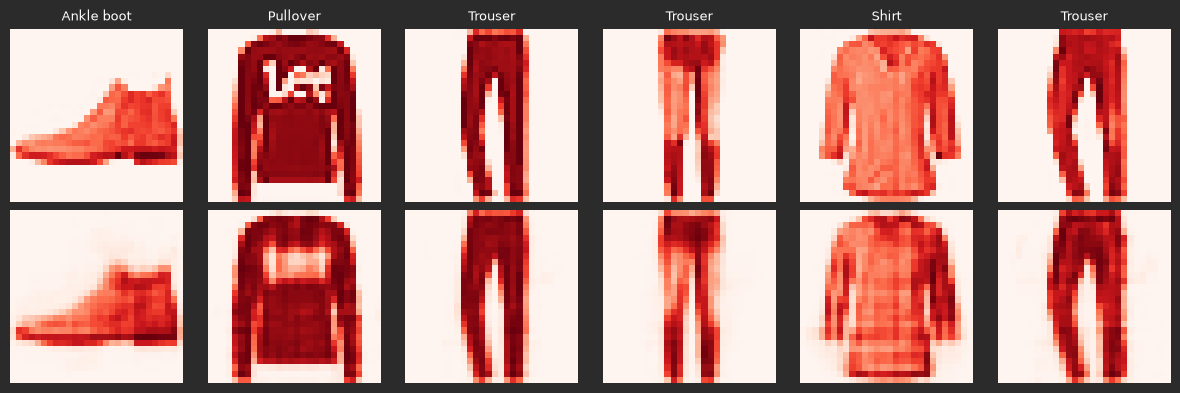

In [3]:
main(config2)


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 128
Dropout:          0.4
Optimizer:        SGD

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: SGD
Dropout: 0.4

Iniciando entrenamiento... Opti -> SGD | Drop -> 0.4 | Z dimension -> 128 | Batch size -> 100
Época 01/10 | Train MSE: 0.16907 | Valid MSE: 0.16891
Época 02/10 | Train MSE: 0.16750 | Valid MSE: 0.16734
Época 03/10 | Train MSE: 0.16598 | Valid MSE: 0.16582
Época 04/10 | Train MSE: 0.16428 | Valid MSE: 0.16411
Época 05/10 | Train MSE: 0.16229 | Valid MSE: 0.16211
Época 06/10 | Train MSE: 0.15994 | Valid MSE: 0.15975
Época 07/10 | Train MSE: 0.15720 | Valid MSE: 0.15701
Época 08/10 | Train MSE: 0.15406 | Valid MSE: 0.15386
Época 09/10 | Train MSE: 0.15052 | Valid MSE: 0.15031
Época 10/10 | Train MSE: 0.14660 | Valid MSE:

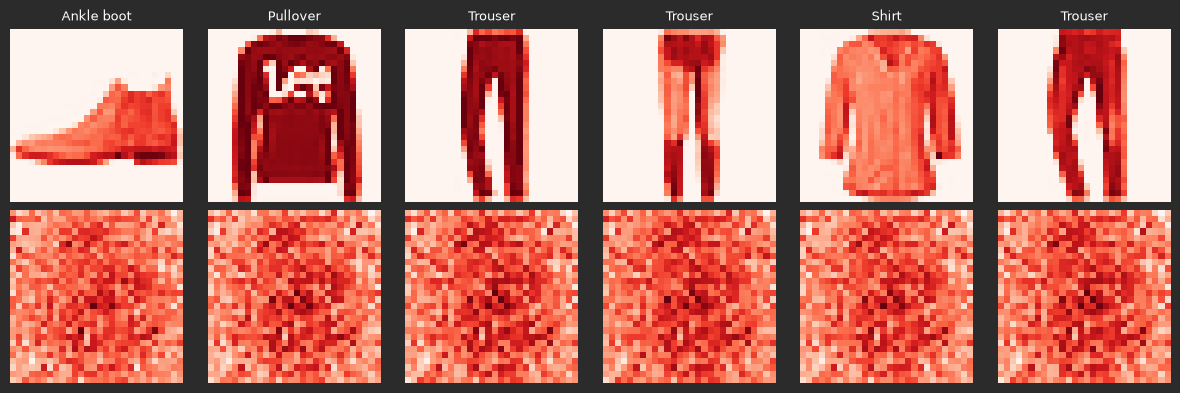

In [4]:
main(config3)

In [5]:
main(config4)


========== CONFIGURATION ==========
Seed:             42
Batch size:       100
Epochs:           10
Latent dimension: 256
Dropout:          0.1
Optimizer:        Adam

========== ENVIRONMENT ==========
PyTorch: 2.6.0+cu124
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Cantidad de imágenes:
Train: 50000
Validation: 10000
Test: 10000

Optimizador: Adam
Dropout: 0.1

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.1 | Z dimension -> 256 | Batch size -> 100
Época 01/10 | Train MSE: 0.01568 | Valid MSE: 0.01584
Época 02/10 | Train MSE: 0.01110 | Valid MSE: 0.01127
Época 03/10 | Train MSE: 0.00939 | Valid MSE: 0.00957
Época 04/10 | Train MSE: 0.00840 | Valid MSE: 0.00860
Época 05/10 | Train MSE: 0.00777 | Valid MSE: 0.00798
Época 06/10 | Train MSE: 0.00736 | Valid MSE: 0.00759
Época 07/10 | Train MSE: 0.00702 | Valid MSE: 0.00725


KeyboardInterrupt: 

In [ ]:
main(config5)

In [ ]:
main(config6)

In [ ]:
main(config7)

In [ ]:
config9 = Config(latent_dim=1024, dropout_p=0.1, batch_size=256, showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)
main(config9)

config8 = Config(latent_dim=2048, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)
main(config8)



In [ ]:
config10 = Config(latent_dim=64, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False, batch_size=1028,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)
main(config10)

In [ ]:
config11 = Config(latent_dim=64, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False, batch_size=4096,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)
main(config11)

In [ ]:
config12 = Config(latent_dim=64, dropout_p=0.1, showSample=False, showDimentions=False,
                 showUntrained=False, batch_size=48,
                 showLoss=False, showTrained=True, showDimentions2=False, showEpochData=True)
main(config12)